# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation and modules notebooks are not produced — this unconditional expression
notebook follows signatures directly.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus). Per the **derive-don't-inherit** mandate
we do not inherit that pair. We score a **broad EMT-TF candidate panel** (Snail/Zeb/Twist plus other
mesenchymal families — FOXC, PRRX, SOX, ID — per the Kürten lesson), gate on a detectable-expression
floor, and pick the two most pseudotime-discriminating factors (one at each end) for the overlay.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 9698 | pseudotime range 0.0 -> 8.65


### Derive the end-specific EMT-TFs (data-driven, detection-gated)
For each candidate TF: fraction of cells expressing, mean expression in the early (root) vs late
(terminus) pseudotime tercile, and Spearman correlation with pseudotime. Factors below a **3 %
expression floor** are too sparse to overlay and are dropped. Among the survivors, the most negative
pseudotime-correlation marks the root end and the most positive marks the terminus.

In [4]:
panel = ['SNAI1','SNAI2','SNAI3','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2',
         'SOX4','SOX9','TBX3','ID1','ID2','ID3','LEF1','TCF3','TCF4','RUNX2','GSC','MSX1','MSX2','NR2F1']
present = [g for g in panel if g in adata.var_names]
absent  = [g for g in panel if g not in adata.var_names]
print('candidates present:', present)
print('candidates absent from filtered matrix:', absent)
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,_ = spearmanr(tn, x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
pd.set_option('display.width', 160)
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\ndetectable EMT-TFs above 3% floor: {ok.TF.tolist()}')
print(f'derived pair: {early_tf} (early/root end) <-> {late_tf} (late/terminus end)')

candidates present: ['SNAI1', 'SNAI2', 'SNAI3', 'ZEB1', 'ZEB2', 'TWIST1', 'TWIST2', 'FOXC1', 'PRRX1', 'PRRX2', 'SOX4', 'SOX9', 'TBX3', 'ID1', 'ID2', 'ID3', 'LEF1', 'TCF3', 'TCF4', 'RUNX2', 'GSC', 'MSX1', 'NR2F1']
candidates absent from filtered matrix: ['FOXC2', 'MSX2']
    TF  frac_expr  mean_early  mean_late  rho_vs_t
  TCF4      0.253       0.452      0.067    -0.436
  SOX9      0.288       0.449      0.095    -0.359
   ID2      0.531       0.800      0.294    -0.345
   ID1      0.504       0.697      0.383    -0.226
 NR2F1      0.088       0.083      0.021    -0.178
 SNAI1      0.060       0.060      0.011    -0.156
TWIST2      0.035       0.026      0.005    -0.142
  MSX1      0.228       0.146      0.083    -0.118
  ZEB1      0.023       0.019      0.004    -0.106
  SOX4      0.970       2.234      2.000    -0.106
 FOXC1      0.035       0.025      0.006    -0.097
  LEF1      0.109       0.063      0.043    -0.096
 RUNX2      0.056       0.031      0.011    -0.096
TWIST1      0.2

### EMT-TF expression overlay (deliverable)
House **categorical** style (matching the reference): grey manifold, thresholded expressers of the two
end-specific factors coloured (early = blue, late = red) — *not* a continuous colormap.
`figsize=(3.5,1.5)`, pseudotime left→right, `size=30`. Each factor is thresholded at the upper quartile
of expression among its expressing cells; draw order is by abundance (more widely-expressed first,
sparser on top).

overlay thresholds (upper quartile among expressers): {'TCF4': 1.087, 'TBX3': 1.443} | cells shown: {'TCF4': 613, 'TBX3': 1714}
TCF4: 25.3% expressing; 613 shown (upper quartile), mean pseudotime of shown cells = 0.24 (all cells = 0.57)
TBX3: 70.7% expressing; 1714 shown (upper quartile), mean pseudotime of shown cells = 0.73 (all cells = 0.57)
shown-cell pseudotime separation (late TBX3 - early TCF4) = +0.49
saved expression.pdf


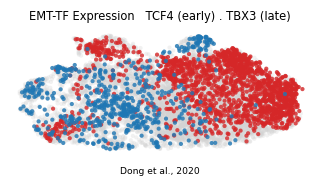

In [5]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) . {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Dong et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown (upper quartile), '
          f'mean pseudotime of shown cells = {tn[m].mean():.2f} (all cells = {tn.mean():.2f})')
sep = tn[sel[late_tf]].mean() - tn[sel[early_tf]].mean()
print(f'shown-cell pseudotime separation (late {late_tf} - early {early_tf}) = {sep:+.2f}')
print('saved expression.pdf')